<a href="https://colab.research.google.com/github/Trinaldi3/Probabilitas-dan-Statistika/blob/main/Uji_Validitas_dan_Reliabilitas_TriNaldi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 Uji Validitas dan Reliabilitas Instrumen


Langkah 1 – Persiapan Lingkungan dan Impor Pustaka

In [1]:
import re
import pandas as pd
import numpy as np
from scipy import stats
from IPython.display import display
from google.colab import files

Langkah 2 – Unggah Berkas Data


In [2]:
up = files.upload()
nama_file = list(up.keys())[0]
print("File terbaca:", nama_file)

Saving Kuesioner Penggunaan AI dan Lifestyle Media Sosial Mahasiswa (Jawaban).xlsx to Kuesioner Penggunaan AI dan Lifestyle Media Sosial Mahasiswa (Jawaban).xlsx
File terbaca: Kuesioner Penggunaan AI dan Lifestyle Media Sosial Mahasiswa (Jawaban).xlsx


Langkah 3 – Membaca Data dan Memisahkan Butir

Pada data ini kolom non-butir ada **6**, yaitu *Timestamp*, *Kelas*, *Jenis Kelamin*, jumlah platform AI, jumlah platform berbayar, dan durasi gadget. Karena itu `JUMLAH_KOLOM_DEMOGRAFI` diubah dari 5 (nilai contoh pada modul) menjadi 6. Jika tetap 5, kolom durasi gadget ikut terbaca sebagai butir dan menyebabkan error pada Langkah 5.

In [23]:
JUMLAH_KOLOM_DEMOGRAFI = 6

df = pd.read_excel(nama_file)
butir = df.iloc[:, JUMLAH_KOLOM_DEMOGRAFI:]

print("Jumlah responden :", len(df))
print("Jumlah butir     :", butir.shape[1])
print("Data kosong      :", int(butir.isna().sum().sum()))

Jumlah responden : 30
Jumlah butir     : 29
Data kosong      : 0


In [24]:
# Gambaran singkat responden (data demografi)
print(df["Kelas"].value_counts(), "\n")
print(df["Jenis Kelamin"].value_counts(), "\n")
print(df.iloc[:, 5].value_counts())

Kelas
3 TI F    30
Name: count, dtype: int64 

Jenis Kelamin
Perempuan    18
Laki-laki    12
Name: count, dtype: int64 

Berapa durasi rata-rata kamu menggunakan gadget per hari, mulai dari kebutuhan harian sampai dengan hiburan?
4 – 7 jam     19
7 – 10 jam     7
> 10 jam       4
Name: count, dtype: int64


Langkah 4 – Mengubah Jawaban Likert Menjadi Angka

In [5]:
skala = {
    "Sangat Tidak Setuju (STS)": 1,
    "Tidak Setuju (TS)": 2,
    "Netral (N)": 3,
    "Setuju (S)": 4,
    "Sangat Setuju (SS)": 5,
}

num = butir.apply(lambda kolom: kolom.astype(str).str.strip().map(skala))

# Harus 0. Jika lebih dari 0, ada jawaban yang tidak terbaca.
print("Sel yang gagal dikonversi:", int(num.isna().sum().sum()))
num.head()

Sel yang gagal dikonversi: 0


,Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI hampir setiap kali mendapatkan tugas atau projek kuliah.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari penyelesaian soal atau permasalahan dalam tugas kuliah.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari ide atau inspirasi saat mengerjakan tugas atau projek.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk memahami materi kuliah yang belum saya kuasai.],"Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk menyusun atau memperbaiki tulisan dalam tugas kuliah, misalnya laporan atau makalah.]",Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk membuat atau memperbaiki kode program pada tugas atau projek.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan lebih dari satu platform AI untuk menyelesaikan tugas atau projek kuliah.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya merasa perlu menggunakan AI setiap kali mendapatkan tugas atau projek kuliah.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya merasa kesulitan menyelesaikan tugas kuliah tanpa bantuan AI.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya cenderung langsung mengikuti jawaban AI tanpa mempertimbangkan sumber lain.],...,Kebiasaan penggunaan teknologi digital [Konsentrasi saya mudah terganggu oleh gadget ketika sedang mengerjakan tugas kuliah.],Prokrastinasi akademik [Saya cenderung menunggu hingga mendekati deadline untuk mulai mengerjakan tugas.],Prokrastinasi akademik [Saya sering menunda tugas karena merasa tugas tersebut dapat diselesaikan dengan cepat menggunakan AI.],Prokrastinasi akademik [Saya sering menyelesaikan tugas kuliah dalam waktu yang sangat dekat dengan batas pengumpulan.],Prokrastinasi akademik [Saya sering harus mengerjakan beberapa tugas sekaligus karena sebelumnya menunda pengerjaannya.],Respon emosional [Saya merasa tertekan ketika harus menyelesaikan tugas dalam waktu singkat akibat menunda pengerjaannya.],Respon emosional [Saya merasa panik ketika beberapa tugas yang saya tunda memiliki batas waktu pengumpulan yang berdekatan.],Respon emosional [Saya merasa kurang puas dengan hasil tugas yang dikerjakan terburu-buru menjelang deadline.],Respon emosional [Saya merasa gelisah ketika mengingat tugas yang belum saya kerjakan.],Respon emosional [Saya merasa menyesal karena hasil tugas mungkin bisa lebih baik apabila dikerjakan lebih awal.]
0,2,4,4,4,4,4,4,2,2,2,...,1,2,2,2,2,4,4,4,4,4
1,4,4,4,4,4,4,4,4,2,2,...,4,4,4,4,4,4,4,4,4,4
2,5,5,5,5,5,5,5,5,4,4,...,5,2,5,5,5,5,5,5,5,5
3,4,5,5,5,4,4,4,4,2,2,...,4,4,2,5,4,4,4,2,5,4
4,5,4,5,5,5,4,5,5,4,1,...,4,1,2,1,2,5,5,4,4,4


Langkah 5 – Mengelompokkan Butir per Dimensi
Setiap dimensi diberi huruf (A–E) supaya butir bisa dirujuk dengan kode seperti A1, B3, dan seterusnya.

In [6]:
dimensi = {}
for kolom in butir.columns:
    nama = re.match(r"^(.*?) \[", kolom).group(1)
    dimensi.setdefault(nama, []).append(kolom)

huruf = {nama: chr(65 + i) for i, nama in enumerate(dimensi)}

for nama, daftar in dimensi.items():
    print(f"{huruf[nama]}. {nama}: {len(daftar)} butir")

A. Penggunaan AI pada tugas atau projek kuliah: 7 butir
B. Aspek Psikologis penggunaan AI pada tugas atau projek kuliah: 7 butir
C. Kebiasaan penggunaan teknologi digital: 6 butir
D. Prokrastinasi akademik: 4 butir
E. Respon emosional: 5 butir


Langkah 6 – Uji Validitas (Korelasi Pearson Butir–Total)

In [7]:
n = len(num)
t = stats.t.ppf(0.975, n - 2)
r_tabel = t / np.sqrt((n - 2) + t**2)
print(f"n = {n} | r tabel (α=0,05; df={n-2}) = {r_tabel:.3f}")

hasil_validitas = []
for nama, daftar in dimensi.items():
    x = num[daftar]
    total = x.sum(axis=1)
    for i, kolom in enumerate(daftar, 1):
        r, p = stats.pearsonr(x[kolom], total)
        r_koreksi, _ = stats.pearsonr(x[kolom], total - x[kolom])
        hasil_validitas.append({
            "Dimensi": nama,
            "Butir": f"{huruf[nama]}{i}",
            "r hitung": round(r, 3),
            "Corrected r": round(r_koreksi, 3),
            "p-value": round(p, 4),
            "Keterangan": "Valid" if r > r_tabel else "Tidak valid",
        })

tabel_validitas = pd.DataFrame(hasil_validitas)
tabel_validitas

n = 30 | r tabel (α=0,05; df=28) = 0.361


,Dimensi,Butir,r hitung,Corrected r,p-value,Keterangan
0,Penggunaan AI pada tugas atau projek kuliah,A1,0.790,0.668,0.0000,Valid
1,Penggunaan AI pada tugas atau projek kuliah,A2,0.691,0.585,0.0000,Valid
2,Penggunaan AI pada tugas atau projek kuliah,A3,0.627,0.481,0.0002,Valid
3,Penggunaan AI pada tugas atau projek kuliah,A4,0.554,0.424,0.0015,Valid
4,Penggunaan AI pada tugas atau projek kuliah,A5,0.722,0.495,0.0000,Valid
5,Penggunaan AI pada tugas atau projek kuliah,A6,0.800,0.723,0.0000,Valid
6,Penggunaan AI pada tugas atau projek kuliah,A7,0.654,0.548,0.0001,Valid
7,Aspek Psikologis penggunaan AI pada tugas atau...,B1,0.710,0.605,0.0000,Valid
8,Aspek Psikologis penggunaan AI pada tugas atau...,B2,0.780,0.685,0.0000,Valid
9,Aspek Psikologis penggunaan AI pada tugas atau...,B3,0.710,0.617,0.0000,Valid


In [8]:
# Ringkasan jumlah butir valid per dimensi
tabel_validitas.groupby("Dimensi", sort=False)["Keterangan"].value_counts().unstack(fill_value=0)

Keterangan,Valid
Dimensi,
Penggunaan AI pada tugas atau projek kuliah,7
Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,7
Kebiasaan penggunaan teknologi digital,6
Prokrastinasi akademik,4
Respon emosional,5


Langkah 7 – Uji Reliabilitas (Cronbach's Alpha)

In [9]:
def cronbach_alpha(x):
    k = x.shape[1]
    return k / (k - 1) * (1 - x.var(ddof=1).sum() / x.sum(axis=1).var(ddof=1))

def kategori(a):
    return ("Sangat baik" if a >= 0.90 else "Baik" if a >= 0.80
            else "Reliabel" if a >= 0.70 else "Tidak reliabel")

hasil_reliabilitas = []
alpha_dihapus = []

for nama, daftar in dimensi.items():
    x = num[daftar]
    a = cronbach_alpha(x)
    hasil_reliabilitas.append({
        "Dimensi": nama,
        "Jumlah butir": len(daftar),
        "Cronbach's alpha": round(a, 3),
        "Kategori": kategori(a),
    })
    for i, kolom in enumerate(daftar, 1):
        if len(daftar) > 2:
            alpha_dihapus.append({
                "Dimensi": nama,
                "Butir": f"{huruf[nama]}{i}",
                "Alpha jika dihapus": round(cronbach_alpha(x.drop(columns=kolom)), 3),
            })

tabel_reliabilitas = pd.DataFrame(hasil_reliabilitas)
tabel_alpha_dihapus = pd.DataFrame(alpha_dihapus)

display(tabel_reliabilitas)
display(tabel_alpha_dihapus)

,Dimensi,Jumlah butir,Cronbach's alpha,Kategori
0,Penggunaan AI pada tugas atau projek kuliah,7,0.799,Reliabel
1,Aspek Psikologis penggunaan AI pada tugas atau...,7,0.886,Baik
2,Kebiasaan penggunaan teknologi digital,6,0.890,Baik
3,Prokrastinasi akademik,4,0.860,Baik
4,Respon emosional,5,0.928,Sangat baik


,Dimensi,Butir,Alpha jika dihapus
0,Penggunaan AI pada tugas atau projek kuliah,A1,0.744
1,Penggunaan AI pada tugas atau projek kuliah,A2,0.768
2,Penggunaan AI pada tugas atau projek kuliah,A3,0.782
3,Penggunaan AI pada tugas atau projek kuliah,A4,0.791
4,Penggunaan AI pada tugas atau projek kuliah,A5,0.808
5,Penggunaan AI pada tugas atau projek kuliah,A6,0.746
6,Penggunaan AI pada tugas atau projek kuliah,A7,0.775
7,Aspek Psikologis penggunaan AI pada tugas atau...,B1,0.879
8,Aspek Psikologis penggunaan AI pada tugas atau...,B2,0.869
9,Aspek Psikologis penggunaan AI pada tugas atau...,B3,0.877


In [10]:
# Butir yang alpha-jika-dihapusnya lebih tinggi daripada alpha dimensinya (perlu ditinjau)
cek = tabel_alpha_dihapus.merge(tabel_reliabilitas[["Dimensi", "Cronbach's alpha"]], on="Dimensi")
cek[cek["Alpha jika dihapus"] > cek["Cronbach's alpha"]]

,Dimensi,Butir,Alpha jika dihapus,Cronbach's alpha
4,Penggunaan AI pada tugas atau projek kuliah,A5,0.808,0.799


 Langkah 8 – Menggabungkan dan Mengunduh Hasil

In [18]:
gabung = tabel_validitas.merge(tabel_alpha_dihapus, on=["Dimensi", "Butir"], how="left")

with pd.ExcelWriter("hasil_uji_validitas_reliabilitas.xlsx") as w:
    gabung.to_excel(w, sheet_name="Validitas", index=False)
    tabel_reliabilitas.to_excel(w, sheet_name="Reliabilitas", index=False)

files.download("hasil_uji_validitas_reliabilitas.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
Latihan

Latihan 2 – Perbandingan kriteria r hitung dan corrected r ≥ 0,30

In [19]:
valid_r = (tabel_validitas["r hitung"] > r_tabel).sum()
valid_rc = (tabel_validitas["Corrected r"] >= 0.30).sum()
print(f"Butir valid berdasarkan r hitung > r tabel ({r_tabel:.3f}) : {valid_r} dari {len(tabel_validitas)}")
print(f"Butir valid berdasarkan corrected r ≥ 0,30              : {valid_rc} dari {len(tabel_validitas)}")

# Selisih r hitung dan corrected r
tabel_validitas["Selisih"] = (tabel_validitas["r hitung"] - tabel_validitas["Corrected r"]).round(3)
print()
print("Rata-rata selisih per dimensi:")
print(tabel_validitas.groupby("Dimensi", sort=False)["Selisih"].mean().round(3))
print()
print("Butir dengan selisih terbesar:")
display(tabel_validitas.sort_values("Selisih", ascending=False).head(3)[["Butir", "r hitung", "Corrected r", "Selisih"]])

Butir valid berdasarkan r hitung > r tabel (0.361) : 29 dari 29
Butir valid berdasarkan corrected r ≥ 0,30              : 29 dari 29

Rata-rata selisih per dimensi:
Dimensi
Penggunaan AI pada tugas atau projek kuliah                     0.131
Aspek Psikologis penggunaan AI pada tugas atau projek kuliah    0.092
Kebiasaan penggunaan teknologi digital                          0.094
Prokrastinasi akademik                                          0.132
Respon emosional                                                0.069
Name: Selisih, dtype: float64

Butir dengan selisih terbesar:


,Butir,r hitung,Corrected r,Selisih
4,A5,0.722,0.495,0.227
22,D3,0.803,0.629,0.174
2,A3,0.627,0.481,0.146


Latihan 3 – Membuang satu butir dan menguji ulang


Pada data ini tidak ada butir yang tidak valid, sehingga butir yang dicoba dibuang dipilih berdasarkan nilai *alpha jika dihapus*. Hanya butir **A5** yang membuat alpha dimensinya naik jika dihapus, jadi butir inilah yang dipakai sebagai percobaan.

In [20]:
nama_A = [k for k, v in huruf.items() if v == "A"][0]
kolom_A5 = dimensi[nama_A][4]          # butir kelima pada dimensi A
print("Butir A5:", kolom_A5)

x_awal = num[dimensi[nama_A]]
x_baru = x_awal.drop(columns=kolom_A5)
print(f"\nAlpha dimensi A sebelum A5 dibuang: {cronbach_alpha(x_awal):.3f}  ({kategori(cronbach_alpha(x_awal))})")
print(f"Alpha dimensi A sesudah A5 dibuang : {cronbach_alpha(x_baru):.3f}  ({kategori(cronbach_alpha(x_baru))})")

# Uji ulang validitas dan alpha-jika-dihapus untuk 6 butir yang tersisa
total_baru = x_baru.sum(axis=1)
ulang = []
for i, kolom in enumerate(x_baru.columns):
    kode = f"A{dimensi[nama_A].index(kolom) + 1}"
    r, p = stats.pearsonr(x_baru[kolom], total_baru)
    rk, _ = stats.pearsonr(x_baru[kolom], total_baru - x_baru[kolom])
    ulang.append({
        "Butir": kode,
        "r hitung": round(r, 3),
        "Corrected r": round(rk, 3),
        "Keterangan": "Valid" if r > r_tabel else "Tidak valid",
        "Alpha jika dihapus": round(cronbach_alpha(x_baru.drop(columns=kolom)), 3),
    })
display(pd.DataFrame(ulang))

Butir A5: Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk menyusun atau memperbaiki tulisan dalam tugas kuliah, misalnya laporan atau makalah.]

Alpha dimensi A sebelum A5 dibuang: 0.799  (Reliabel)
Alpha dimensi A sesudah A5 dibuang : 0.808  (Baik)


,Butir,r hitung,Corrected r,Keterangan,Alpha jika dihapus
0,A1,0.803,0.644,Valid,0.763
1,A2,0.762,0.648,Valid,0.761
2,A3,0.600,0.400,Valid,0.817
3,A4,0.627,0.476,Valid,0.796
4,A6,0.832,0.743,Valid,0.740
5,A7,0.690,0.562,Valid,0.780


Latihan 4 – Pengaruh ukuran sampel

In [21]:
def r_tabel_n(m):
    tt = stats.t.ppf(0.975, m - 2)
    return tt / np.sqrt((m - 2) + tt**2)

def jumlah_valid(data):
    m = len(data)
    rt = r_tabel_n(m)
    jml = 0
    for nama, daftar in dimensi.items():
        x = data[daftar]
        tot = x.sum(axis=1)
        for kolom in daftar:
            r, _ = stats.pearsonr(x[kolom], tot)
            jml += int(r > rt)
    return rt, jml

# Subset acak sesuai contoh modul
sub = num.sample(20, random_state=1)
rt20, v20 = jumlah_valid(sub)
print(f"Subset n=20 (random_state=1): r tabel = {rt20:.3f}, butir valid = {v20} dari {num.shape[1]}")

# Perbandingan beberapa ukuran sampel
baris = []
for m in [10, 15, 20, 25, 30]:
    d = num if m == len(num) else num.sample(m, random_state=1)
    rt, jv = jumlah_valid(d)
    baris.append({"n": m, "df": m - 2, "r tabel": round(rt, 3), "Butir valid": jv, "Butir tidak valid": num.shape[1] - jv})
pd.DataFrame(baris)

Subset n=20 (random_state=1): r tabel = 0.444, butir valid = 28 dari 29


,n,df,r tabel,Butir valid,Butir tidak valid
0,10,8,0.632,25,4
1,15,13,0.514,26,3
2,20,18,0.444,28,1
3,25,23,0.396,29,0
4,30,28,0.361,29,0



Tambahan Laporan 3 – Distribusi Data dan Analisis Hubungan Antar Dimensi

Langkah 9 – Menghitung Skor Tiap Dimensi

Skor dimensi adalah rata-rata butir dalam dimensi tersebut (skala 1–5), sehingga dimensi dengan jumlah butir berbeda tetap dapat dibandingkan.

In [25]:
skor = pd.DataFrame({
    huruf[nama]: num[daftar].mean(axis=1)
    for nama, daftar in dimensi.items()
})
skor.head()

,A,B,C,D,E
0,3.714286,2.000000,1.833333,2.00,4.0
1,4.000000,2.571429,4.000000,4.00,4.0
2,5.000000,4.571429,4.833333,4.25,5.0
3,4.428571,2.428571,3.833333,3.75,3.8
4,4.714286,2.714286,2.500000,1.50,4.4


Langkah 10 – Distribusi Data (Statistik Deskriptif, Histogram, dan Uji Normalitas Shapiro-Wilk)

,Rata-rata,Simpangan baku,Min,Median,Maks,Skewness
A,4.576,0.407,3.714,4.643,5.0,-0.526
B,2.862,1.111,1.000,2.786,5.0,0.018
C,3.589,1.239,1.167,3.917,5.0,-0.487
D,3.042,1.377,1.000,3.000,5.0,-0.078
E,4.140,1.159,1.000,4.500,5.0,-2.083


,Dimensi,W,p-value,Distribusi
0,A,0.874,0.0020,Tidak normal
1,B,0.972,0.5813,Normal
2,C,0.905,0.0111,Tidak normal
3,D,0.916,0.0206,Tidak normal
4,E,0.685,0.0000,Tidak normal


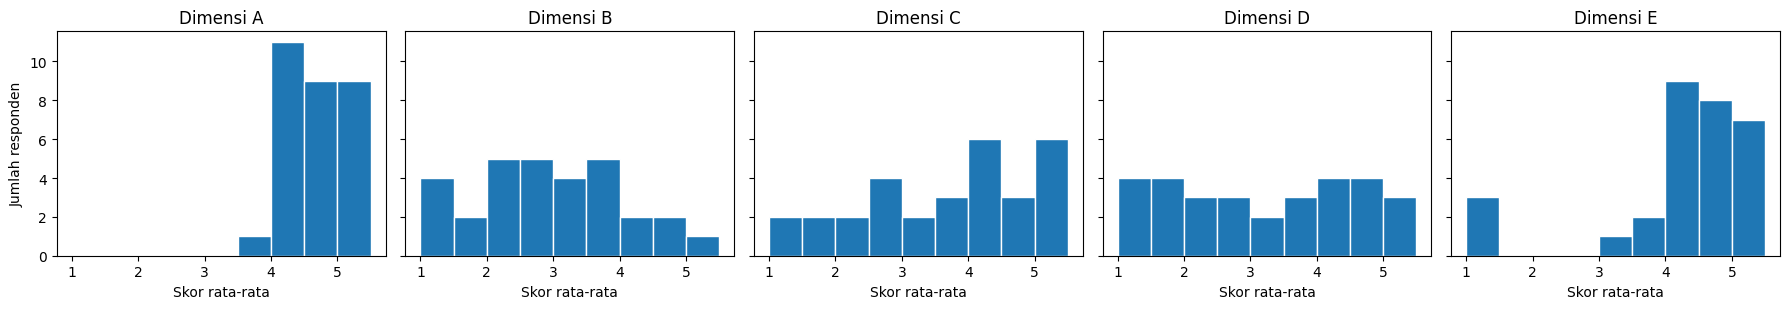

In [26]:
import matplotlib.pyplot as plt

desk = skor.agg(["mean", "std", "min", "median", "max", "skew"]).T.round(3)
desk.columns = ["Rata-rata", "Simpangan baku", "Min", "Median", "Maks", "Skewness"]

sw = []
for h in skor.columns:
    w, p = stats.shapiro(skor[h])
    sw.append({"Dimensi": h, "W": round(w, 3), "p-value": round(p, 4),
               "Distribusi": "Normal" if p > 0.05 else "Tidak normal"})
tabel_normal = pd.DataFrame(sw)

display(desk)
display(tabel_normal)

fig, ax = plt.subplots(1, 5, figsize=(18, 3.2), sharey=True)
for a, h in zip(ax, skor.columns):
    a.hist(skor[h], bins=np.arange(1, 5.51, 0.5), edgecolor="white")
    a.set_title(f"Dimensi {h}")
    a.set_xlabel("Skor rata-rata")
ax[0].set_ylabel("Jumlah responden")
plt.tight_layout()
plt.show()

Langkah 11 – Analisis Hubungan Antar Dimensi (Korelasi Spearman)

Spearman dipilih karena data berskala Likert (ordinal) dan uji Shapiro-Wilk pada Langkah 10 menunjukkan sebagian besar dimensi tidak berdistribusi normal.

,A,B,C,D,E
A,1.000,0.157,0.424,0.202,0.234
B,0.157,1.000,0.327,0.157,0.344
C,0.424,0.327,1.000,0.588,-0.196
D,0.202,0.157,0.588,1.000,-0.028
E,0.234,0.344,-0.196,-0.028,1.000


,A,B,C,D,E
A,0.0000,0.4064,0.0196,0.2852,0.2135
B,0.4064,0.0000,0.0782,0.4087,0.0630
C,0.0196,0.0782,0.0000,0.0006,0.2981
D,0.2852,0.4087,0.0006,0.0000,0.8815
E,0.2135,0.0630,0.2981,0.8815,0.0000


,Pasangan,r Spearman,p-value,Kekuatan,"Signifikan (α=0,05)"
0,A – B,0.157,0.4064,Sangat lemah,Tidak
1,A – C,0.424,0.0196,Sedang,Ya
2,A – D,0.202,0.2852,Lemah,Tidak
3,A – E,0.234,0.2135,Lemah,Tidak
4,B – C,0.327,0.0782,Lemah,Tidak
5,B – D,0.157,0.4087,Sangat lemah,Tidak
6,B – E,0.344,0.0630,Lemah,Tidak
7,C – D,0.588,0.0006,Sedang,Ya
8,C – E,-0.196,0.2981,Sangat lemah,Tidak
9,D – E,-0.028,0.8815,Sangat lemah,Tidak


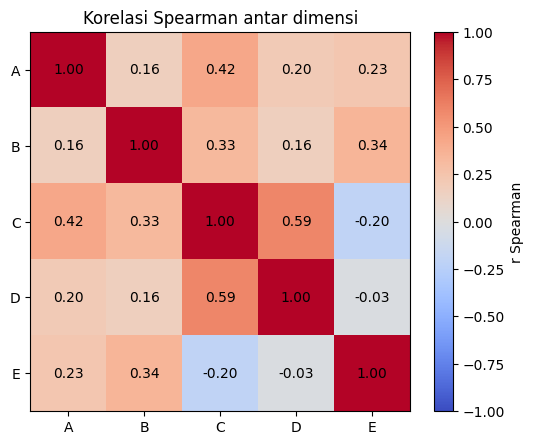

In [27]:
kor = skor.corr(method="spearman").round(3)
pval = pd.DataFrame(
    {a: {b: stats.spearmanr(skor[a], skor[b])[1] for b in skor.columns} for a in skor.columns}
).round(4)

def kekuatan(r):
    r = abs(r)
    return ("Sangat lemah" if r < 0.20 else "Lemah" if r < 0.40 else
            "Sedang" if r < 0.60 else "Kuat" if r < 0.80 else "Sangat kuat")

pasangan = []
kode = list(skor.columns)
for i in range(len(kode)):
    for j in range(i + 1, len(kode)):
        r = kor.iloc[i, j]; p = pval.iloc[i, j]
        pasangan.append({"Pasangan": f"{kode[i]} – {kode[j]}", "r Spearman": r, "p-value": p,
                         "Kekuatan": kekuatan(r), "Signifikan (α=0,05)": "Ya" if p < 0.05 else "Tidak"})
tabel_korelasi = pd.DataFrame(pasangan)

display(kor)
display(pval)
display(tabel_korelasi)

plt.figure(figsize=(5.5, 4.5))
plt.imshow(kor, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="r Spearman")
plt.xticks(range(5), kor.columns); plt.yticks(range(5), kor.index)
for i in range(5):
    for j in range(5):
        plt.text(j, i, f"{kor.iloc[i, j]:.2f}", ha="center", va="center")
plt.title("Korelasi Spearman antar dimensi")
plt.tight_layout()
plt.show()

Langkah 12 – Menyimpan Hasil Tambahan

In [28]:
with pd.ExcelWriter("hasil_distribusi_korelasi.xlsx") as w:
    skor.round(3).to_excel(w, sheet_name="Skor Dimensi", index=False)
    desk.to_excel(w, sheet_name="Deskriptif")
    tabel_normal.to_excel(w, sheet_name="Normalitas", index=False)
    kor.to_excel(w, sheet_name="Korelasi r")
    pval.to_excel(w, sheet_name="Korelasi p")
    tabel_korelasi.to_excel(w, sheet_name="Pasangan", index=False)

files.download("hasil_distribusi_korelasi.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>